# 17 · Degree-preserving rewiring and E/I contact controls
## Goal
Study how rewiring a fixed degree-4 ring changes FHN E/I dynamics while preserving node identity, degree, individual coupling coefficients and initial fields. Compare ordinary double-edge swaps with swaps that also preserve each node's E/I neighbor counts.

This notebook is self-contained. Run top-to-bottom in a Python kernel with NumPy, SciPy, pandas, Matplotlib, NetworkX and IPython. Earlier notebooks are not runtime dependencies. Results are saved under `results/fhn_ei_degree_rewiring/`; there are 40 main/supplementary conditions plus selected accuracy and longer-window audits.

## Observations from the executed experiment
**13 distinct graphs, 40 conditions, 83 checks passed, seven figures saved and inspected.** Each graph remains connected and degree 4 with 36 nodes, 72 edges, contact coefficient 0.02 and row/column coefficient sums 0.08. Every accepted swap was replayed from the proposal log; every constrained intermediate graph retained every node's E/I counts for assignment 301.

For **assignment 301, phase seed 11 and window 400–1000**, the base has **R=0.219**. After 144 accepted E/I-preserving swaps, seeds 501/502/503 give **R=0.390 / 0.102 / 0.420**, respectively. Thus fixed degrees, local E/I coefficient exposure and initial states do not fix these finite-window observations. The corresponding changes from the matched base are **+0.171 / −0.116 / +0.202**; these are three realized paths, not confidence limits.

Under the same assignment/phase/window, final ordinary paths give **R=0.288 / 0.274 / 0.185**. Both rules have examples of increased and decreased order relative to the matched base across paths and phases; there is no consistent sign in this small comparison. Ordinary final paths change some nodes' E-neighbor counts by **2–3**, whereas the constrained paths change them by **0**. Both rules reduce mean clustering below the base value **0.500** in all sampled snapshots, but the dynamics do not support a universal clustering–order relation.

Source assignment matters. For ordinary seed 501 at 144 swaps and phase 11, ΔR is **+0.070** under assignment 301 and **−0.180** under assignment 302, relative to each assignment's own base. This is a paired source-placement sensitivity example, not an estimate of a population effect.

Window sensitivity is also material. At assignment 301 / phase 11, R changes **0.219 → 0.149** on the base, **0.288 → 0.173** on ordinary 501/144, and **0.390 → 0.290** on constrained 501/144 between 400–1000 and 1400–2000. Selected longer runs do not establish convergence or stable attractors.

For constrained 501/144, independent Radau on **0–200** differs in sampled state coordinates by at most **3.66×10⁻⁹**; tighter DOP853 on **0–1000** differs by **1.52×10⁻⁸**. These selected numerical checks do not certify all trajectories or long-time behavior. Exact graph matrices, node contacts, proposal histories, events, metrics, parameters and software versions are saved alongside the figures.


## Setup and controlled quantities
The unchanged continuous equations are
$$\dot v_i=v_i-v_i^3/3-w_i+0.5+\sum_jG_{ij}s_j(E_j-v_i),\quad\dot w_i=0.08(v_i+0.7-0.8w_i),$$
$$\dot s_j=\sigma(v_j/0.1)(1-s_j)-0.2s_j,\qquad E_j=+3\ (E),\;-3\ (I).$$
There are 36 labeled nodes, 18 E and 18 I sources. Every realized graph is simple, undirected, connected and degree 4 with 72 edges. Its two directed synaptic contacts per undirected edge have $G_{ij}=0.02A_{ij}$: every recipient coefficient sum and every source outgoing coefficient sum is 0.08. Rows are recipients; columns are sources. Source identity and reversal remain fixed across outgoing contacts. v=0 upward crossings measure events without resetting FHN states. Units are dimensionless; gates are graded release, not event-triggered jumps. No delays, noise or plasticity.

The base ring connects each label to offsets ±1 and ±2 modulo 36. The ring drawing is not a physical distance law. Rewiring changes which neurons interact, with no change to individual contact strength.

**Ordinary swaps** retain degrees and connectivity, but can change each recipient's number of E and I neighbors. **E/I-preserving swaps** additionally retain these counts for source assignment 301. Thus they fix per-node E/I coefficient exposure, not actual currents: gate activities and driving forces can still change. Source assignment 302 is a supplementary check on ordinary paths only; the constraints are defined specifically for assignment 301.

In [2]:
from pathlib import Path
import json,platform
import numpy as np
import pandas as pd
import scipy,matplotlib
from scipy.integrate import solve_ivp
from scipy.special import expit
from scipy.sparse import csr_matrix,lil_matrix
from scipy.sparse.csgraph import connected_components
from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
OUT=Path('results/fhn_ei_degree_rewiring');OUT.mkdir(parents=True,exist_ok=True)
SIDE=6;N=SIDE**2;END=1000.;BURN=400.;DT=.5
A_REC,B_REC,EPS=.7,.8,.08;ALPHA,BETA,WIDTH=1.,.2,.1
PHASE_SEEDS=[11,29];G0=.02;ROW_BUDGET=.08
BLUE,ORANGE,GRAY,OLIVE,PINK='#2166AC','#C56A18','#555555','#8A7515','#A3537B'
plt.rcParams.update({'font.size':11,'figure.dpi':110,'savefig.dpi':160,'axes.spines.top':False,
 'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
versions=dict(python=platform.python_version(),numpy=np.__version__,scipy=scipy.__version__,pandas=pd.__version__,matplotlib=matplotlib.__version__)
print(versions)
def save(fig,name):
 fig.savefig(OUT/(name+'.png'),bbox_inches='tight');plt.show();plt.close(fig)
import networkx as nx
import hashlib
versions['networkx']=nx.__version__
SWAP_SEEDS=[501,502,503];LEVELS=[18,144];KINDS=['ordinary','ei_preserving']
KIND_LABEL={'ordinary':'Ordinary','ei_preserving':'E/I-preserving'}
KIND_COLOR={'ordinary':BLUE,'ei_preserving':ORANGE}
LAYOUTS={}
for seed in [301,302]:
 mask=np.ones(N,dtype=bool);mask[np.random.default_rng(seed).choice(N,N//2,replace=False)]=False
 LAYOUTS[f'random_{seed}']=mask
SOURCE=LAYOUTS['random_301']
BASE=nx.Graph();BASE.add_nodes_from(range(N))
for i in range(N):
 for offset in [1,2]:BASE.add_edge(i,(i+offset)%N)
BASE_A=nx.to_numpy_array(BASE,nodelist=range(N));BASE_EDGES={tuple(sorted(e)) for e in BASE.edges()}
BASE_E_DEGREE=BASE_A@SOURCE.astype(int)
GRAPHS={'base':BASE.copy()};GRAPH_META=[dict(graph='base',kind='baseline',swap_seed=0,accepted_swaps=0,attempts=0)]
proposal_rows=[]
def make_path(kind,seed,levels):
 g=BASE.copy();rng=np.random.default_rng(seed);accepted=0;attempt=0;results={}
 while accepted<max(levels):
  attempt+=1
  if attempt>200000:raise RuntimeError('Proposal limit exceeded; do not silently return an incomplete stage')
  edges=sorted(tuple(sorted(e)) for e in g.edges());idx=rng.choice(len(edges),2,replace=False)
  a,b=edges[idx[0]];c,d=edges[idx[1]]
  if rng.integers(2):a,b=b,a
  if rng.integers(2):c,d=d,c
  status='accepted'
  if len({a,b,c,d})<4:status='shared_endpoint'
  elif kind=='ei_preserving' and not (SOURCE[b]==SOURCE[d] and SOURCE[a]==SOURCE[c]):status='source_constraint'
  elif g.has_edge(a,d) or g.has_edge(c,b):status='existing_edge'
  else:
   g.remove_edges_from([(a,b),(c,d)]);g.add_edges_from([(a,d),(c,b)])
   if not nx.is_connected(g):
    g.remove_edges_from([(a,d),(c,b)]);g.add_edges_from([(a,b),(c,d)]);status='disconnects'
  if status=='accepted':accepted+=1
  proposal_rows.append(dict(kind=kind,swap_seed=seed,attempt=attempt,a=a,b=b,c=c,d=d,status=status,accepted_total=accepted))
  if status=='accepted' and accepted in levels:
   key=f'{kind}_{seed}_{accepted}';results[key]=g.copy()
   GRAPH_META.append(dict(graph=key,kind=kind,swap_seed=seed,accepted_swaps=accepted,attempts=attempt))
 return results
for kind in KINDS:
 for seed in SWAP_SEEDS:GRAPHS.update(make_path(kind,seed,LEVELS))
meta=pd.DataFrame(GRAPH_META);proposals=pd.DataFrame(proposal_rows)
proposals.to_csv(OUT/'swap_proposals.csv',index=False);meta.to_csv(OUT/'graph_design.csv',index=False)
ADJ={k:nx.to_numpy_array(g,nodelist=range(N)) for k,g in GRAPHS.items()};G_MATRICES={k:G0*A for k,A in ADJ.items()}
structure_rows=[];contact_rows=[]
for name,g in GRAPHS.items():
 A=ADJ[name];E_edges={tuple(sorted(e)) for e in g.edges()};edegree=A@SOURCE.astype(int)
 for node in range(N):
  for layout,mask in LAYOUTS.items():contact_rows.append(dict(graph=name,layout=layout,node=node,E_neighbors=int((A@mask.astype(int))[node]),I_neighbors=int((A@(~mask).astype(int))[node])))
 structure_rows.append(dict(graph=name,edges=g.number_of_edges(),components=nx.number_connected_components(g),
  clustering=nx.average_clustering(g),mean_path_length=nx.average_shortest_path_length(g),
  laplacian_lambda2=max(0.,float(np.linalg.eigvalsh(4*np.eye(N)-A)[1])),
  replaced_base_edge_fraction=1-len(E_edges&BASE_EDGES)/len(BASE_EDGES),
  E_neighbor_count_max_change=int(abs(edegree-BASE_E_DEGREE).max()),
  same_type_fraction=float((A[np.ix_(SOURCE,SOURCE)].sum()+A[np.ix_(~SOURCE,~SOURCE)].sum())/A.sum()),
  adjacency_sha256=hashlib.sha256(A.astype(np.uint8).tobytes()).hexdigest()))
 pd.DataFrame(A).to_csv(OUT/f'adjacency_{name}.csv',index=False)
 pd.DataFrame(G_MATRICES[name]).to_csv(OUT/f'conductance_{name}.csv',index=False)
structure=meta.merge(pd.DataFrame(structure_rows),on='graph',validate='one_to_one');structure.to_csv(OUT/'graph_structure.csv',index=False)
contacts=pd.DataFrame(contact_rows);contacts.to_csv(OUT/'node_source_contacts.csv',index=False)
pd.DataFrame([dict(layout=k,node=i,source_type='E' if m[i] else 'I') for k,m in LAYOUTS.items() for i in range(N)]).to_csv(OUT/'source_assignments.csv',index=False)
display(structure[['graph','accepted_swaps','attempts','clustering','mean_path_length','replaced_base_edge_fraction','E_neighbor_count_max_change']].round(4))


{'python': '3.12.2', 'numpy': '2.2.6', 'scipy': '1.18.1', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}


,graph,accepted_swaps,attempts,clustering,mean_path_length,replaced_base_edge_fraction,E_neighbor_count_max_change
0,base,0,0,0.5000,4.8857,0.0000,0
1,ordinary_501_18,18,19,0.1806,2.7778,0.4167,2
2,ordinary_501_144,144,173,0.0556,2.5540,0.8750,3
3,ordinary_502_18,18,20,0.1528,2.8159,0.4444,2
4,ordinary_502_144,144,178,0.0694,2.6317,0.7639,3
5,ordinary_503_18,18,24,0.1667,2.7429,0.3611,2
6,ordinary_503_144,144,185,0.1250,2.7143,0.8611,2
7,ei_preserving_501_18,18,106,0.1111,2.7508,0.4583,0
8,ei_preserving_501_144,144,737,0.0556,2.8587,0.8333,0
9,ei_preserving_502_18,18,110,0.1111,2.6825,0.4028,0


## 1. Define what an accepted swap means
Choose two distinct existing edges uniformly from a sorted edge list and randomly orient each: (a,b), (c,d). Reject shared endpoints, existing proposed edges, and disconnections. Otherwise replace them with (a,d), (c,b). Each of the four nodes loses and gains one edge. For the E/I-preserving rule, also require type(b)=type(d) and type(a)=type(c), so every endpoint loses and gains a neighbor of the same source type.

Each of three seeds starts independently from the base ring. Save snapshots after **18 and 144 accepted swaps**, continuing along the same path; the stages are correlated. Rejections do not count toward accepted swaps. All proposals, endpoints, rejection reasons and accepted counts are recorded. The two rules use the same seed labels but their accepted histories differ; these are not matched individual swaps.

Repeated swaps can undo earlier edits. Accepted swap count is not the fraction of distinct edges replaced; both are reported. Connectedness and source constraints select the accessible graphs, and these short paths are not claimed to sample a uniform or mixed graph ensemble. No monotonic change in clustering, path length or dynamics is assumed.

The gallery shows the baseline and six final-stage graphs; node labels are fixed, blue circles are E and orange squares I (assignment 301).

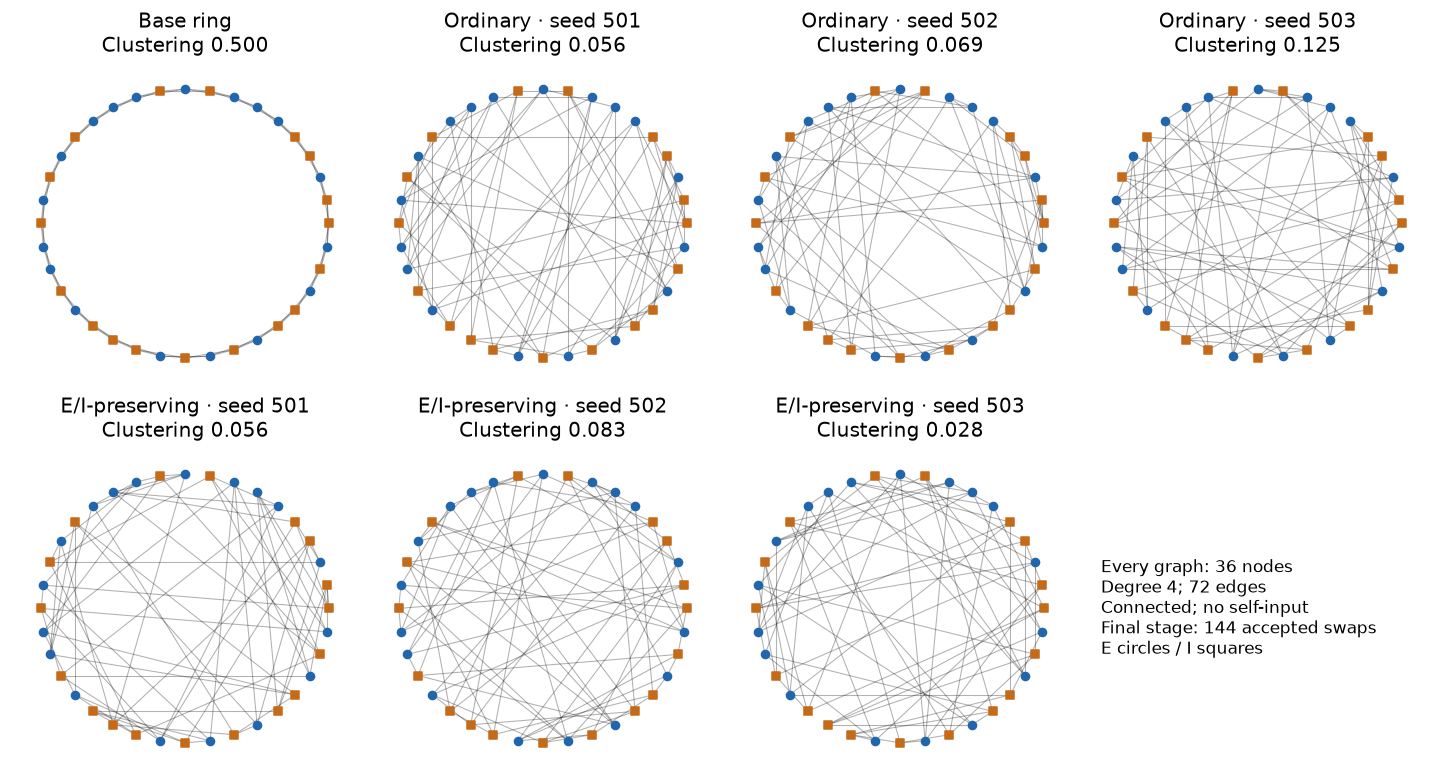

In [4]:
fig,axs=plt.subplots(2,4,figsize=(13,7),layout='constrained');pos=nx.circular_layout(list(range(N)))
keys=['base']+[f'{kind}_{seed}_144' for kind in KINDS for seed in SWAP_SEEDS]
for ax,name in zip(axs.flat,keys):
 g=GRAPHS[name];nx.draw_networkx_edges(g,pos,ax=ax,width=.7,alpha=.3)
 for flag,color,shape in [(True,BLUE,'o'),(False,ORANGE,'s')]:
  nx.draw_networkx_nodes(g,pos,nodelist=np.flatnonzero(SOURCE==flag).tolist(),node_color=color,node_shape=shape,node_size=28,ax=ax)
 row=structure[structure.graph==name].iloc[0]
 title='Base ring' if name=='base' else f'{KIND_LABEL[row.kind]} · seed {row.swap_seed}'
 ax.set_title(title+'\n'+f'Clustering {row.clustering:.3f}');ax.set_axis_off()
axs.flat[-1].set_axis_off();axs.flat[-1].text(.05,.5,'Every graph: 36 nodes\nDegree 4; 72 edges\nConnected; no self-input\nFinal stage: 144 accepted swaps\nE circles / I squares',transform=axs.flat[-1].transAxes,va='center',fontsize=11)
save(fig,'01_rewired_graph_gallery')

## 2. Quantify what the paths change
Lines connect snapshots from the same seed; accepted-swap stages are equally spaced on the categorical axis. Local E/I exposure is held fixed only by the constrained rule. Global E-source coefficient share is 1/2 for both rules because every node has equal outgoing coefficient sum; equal global exposure does not fix its recipient-level distribution. λ₂ is saved as a structural statistic, not used as a stability criterion.

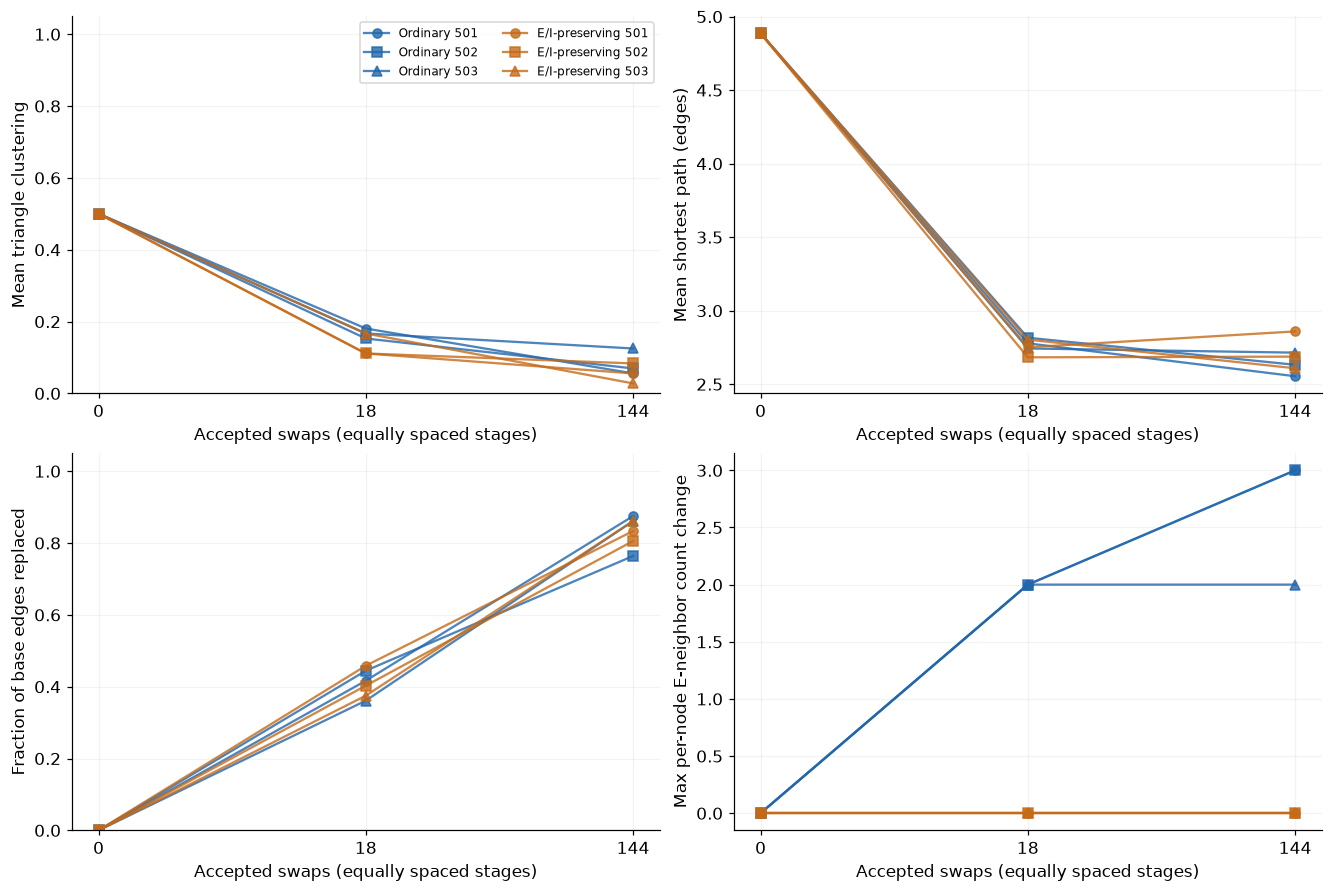

In [6]:
fig,axs=plt.subplots(2,2,figsize=(12,8),layout='constrained');xx=np.arange(3)
metrics=[('clustering','Mean triangle clustering'),('mean_path_length','Mean shortest path (edges)'),('replaced_base_edge_fraction','Fraction of base edges replaced'),('E_neighbor_count_max_change','Max per-node E-neighbor count change')]
for ax,(metric,label) in zip(axs.flat,metrics):
 for kind in KINDS:
  for seed,marker in zip(SWAP_SEEDS,['o','s','^']):
   part=pd.concat([structure[structure.graph=='base'],structure[(structure.kind==kind)&(structure.swap_seed==seed)].sort_values('accepted_swaps')])
   ax.plot(xx,part[metric],marker=marker,color=KIND_COLOR[kind],alpha=.8,label=f'{KIND_LABEL[kind]} {seed}')
 ax.set(xticks=xx,xticklabels=['0','18','144'],xlabel='Accepted swaps (equally spaced stages)',ylabel=label)
 if metric in ['clustering','replaced_base_edge_fraction']:ax.set_ylim(0,1.05)
axs[0,0].legend(fontsize=8,ncol=2)
save(fig,'02_structure_along_swap_paths')
acceptance=proposals.groupby(['kind','swap_seed','status']).size().rename('proposals').reset_index();acceptance.to_csv(OUT/'proposal_outcomes.csv',index=False)


## 3. Integrate the unchanged neuron/synapse equations
DOP853 uses rtol 10⁻¹⁰, atol 10⁻¹² and max step 0.25. The isolated-cycle phase initialization, gate reset to zero, and initial field seeds 11/29 match notebook 16. The same labeled v,w,s fields are used for every graph and source assignment. An analytic sparse Jacobian supports Radau audits.

In [8]:
def inputs(v,s,G,E):return G@(s*E)-v*(G@s)
def rhs_values(y,currents,G,E):
 v,w,s=y.reshape(-1,3).T
 return np.column_stack((v-v**3/3-w+currents+inputs(v,s,G,E),EPS*(v+A_REC-B_REC*w),
  ALPHA*expit(v/WIDTH)*(1-s)-BETA*s)).ravel()
def jacobian(y,G,E):
 n=len(E);v,w,s=y.reshape(n,3).T;q=expit(v/WIDTH);J=lil_matrix((3*n,3*n))
 degree=G@s
 for i in range(n):
  J[3*i,3*i]=1-v[i]**2-degree[i];J[3*i,3*i+1]=-1
  J[3*i+1,3*i]=EPS;J[3*i+1,3*i+1]=-EPS*B_REC
  J[3*i+2,3*i]=ALPHA*q[i]*(1-q[i])*(1-s[i])/WIDTH
  J[3*i+2,3*i+2]=-ALPHA*q[i]-BETA
  for j in G.getrow(i).indices:J[3*i,3*j+2]=G[i,j]*(E[j]-v[i])
 return J.tocsr()
def integrate(initial,G,E,end=END,method='DOP853',rtol=1e-10,atol=1e-12):
 initial=np.asarray(initial,float);G=np.asarray(G,float);E=np.asarray(E,float);n=len(E)
 if initial.shape!=(n,3) or G.shape!=(n,n):raise ValueError('Shape mismatch')
 if not np.isfinite(initial).all() or not np.isfinite(G).all() or not np.isfinite(E).all() or np.any(G<0) or np.any(np.diag(G)!=0):raise ValueError('Invalid state or conductance')
 if np.any(initial[:,2]<0) or np.any(initial[:,2]>1):raise ValueError('Initial gate outside [0,1]')
 Gs=csr_matrix(G);events=[]
 for i in range(n):
  def event(t,y,index=i):return y[3*index]
  event.direction=1;event.terminal=False;events.append(event)
 options={}
 if method in ['Radau','BDF']:options['jac']=lambda t,y:jacobian(y,Gs,E)
 sol=solve_ivp(lambda t,y:rhs_values(y,.5,Gs,E),(0,end),initial.ravel(),method=method,
  rtol=rtol,atol=atol,events=events,dense_output=True,max_step=.25,**options)
 if not sol.success:raise RuntimeError(sol.message)
 return sol
iso=integrate([[2.,-.5,0.]],np.zeros((1,1)),np.array([3.]),end=800.,rtol=1e-10,atol=1e-12)
t0,t1=iso.t_events[0][-2:];PERIOD=t1-t0
INITIAL={};init_rows=[]
for seed in PHASE_SEEDS:
 phases=np.random.default_rng(seed).uniform(0,1,N)
 states=iso.sol(t0+phases*PERIOD).reshape(3,N).T;states[:,2]=0;INITIAL[seed]=states
 for node,(q,z) in enumerate(zip(phases,states)):init_rows.append(dict(phase_seed=seed,node=node,phase_fraction=q,v=z[0],w=z[1],s=z[2]))
pd.DataFrame(init_rows).to_csv(OUT/'initial_states.csv',index=False)
print('Reference isolated period:',PERIOD)

Reference isolated period: 39.474414980238635


## 4. Measure paired dynamics
There are 13 graphs: one shared base plus two snapshots × three seeds × two rules. Assignment 301 is studied on all graphs with both phase fields (**26 conditions**). Assignment 302 is studied on the base and six ordinary snapshots with both phase fields (**14 supplementary conditions**), for **40 total**. The base is simulated once per assignment/phase, not counted again as an independent replicate for every path.

Observe 400–1000. Node frequency is event count/600. Event phase is interpolated between upward v=0 events, never extrapolated; global R averages over times supported by all nodes and records coverage. Per-node ISI and input metrics are saved. Local uncancelled fraction $C=\langle|J_E+J_I|\rangle/\langle|J_E|+|J_I|\rangle$ takes absolute values before node/time averaging; it is not a physiological balance certificate. Centered v,w state spread is also recorded.

Each Δ metric is that condition minus the **same source assignment and phase field on the base ring**. A change with E/I-preserving rewiring shows that fixed degrees and local E/I coefficient counts need not fix the trajectory; it does not identify a single graph statistic as the cause.

In [10]:
def phase_order(phase,mask):
 if not np.any(mask):return np.nan,0.
 valid=np.isfinite(phase[mask]).all(axis=0)
 if not valid.any():return np.nan,0.
 return float(np.abs(np.mean(np.exp(1j*phase[mask][:,valid]),axis=0)).mean()),float(valid.mean())
def measure(sol,mask,G,start=BURN,stop=END):
 times=np.arange(start,stop+DT/10,DT);z=sol.sol(times).reshape(N,3,-1);v,w,s=z[:,0],z[:,1],z[:,2]
 G=csr_matrix(G);E=np.where(mask,3.,-3.)
 JE=inputs(v,s*mask[:,None],G,E[:,None]);JI=inputs(v,s*(~mask)[:,None],G,E[:,None])
 phase=np.full((N,len(times)),np.nan);node_rows=[]
 for i,e in enumerate(sol.t_events):
  recent=e[(e>=start)&(e<=stop)];isi=np.diff(recent)
  if len(e)>=2:
   valid=(times>=e[0])&(times<=e[-1]);phase[i,valid]=np.interp(times[valid],e,2*np.pi*np.arange(len(e)))
  node_rows.append(dict(node=i,source_type='E' if mask[i] else 'I',window_spikes=len(recent),count_frequency=len(recent)/(stop-start),
   period_frequency=float(1/isi.mean()) if len(isi)>=2 else np.nan,isi_cv=float(isi.std()/isi.mean()) if len(isi)>=2 else np.nan,
   mean_E_input=float(JE[i].mean()),mean_I_input=float(JI[i].mean()),rms_E_input=float(np.sqrt(np.mean(JE[i]**2))),rms_I_input=float(np.sqrt(np.mean(JI[i]**2)))))
 nodes=pd.DataFrame(node_rows);centered=z[:,:2]-z[:,:2].mean(axis=0,keepdims=True)
 total=float(np.mean(abs(JE)+abs(JI)));C=float(np.mean(abs(JE+JI))/total) if total>1e-15 else np.nan
 row=dict(state_spread=float(np.sqrt(np.mean(np.sum(centered**2,axis=1)))),mean_count_frequency=float(nodes.count_frequency.mean()),
  std_count_frequency=float(nodes.count_frequency.std(ddof=0)),nodes_with_spikes=int((nodes.window_spikes>0).sum()),
  mean_E_input=float(JE.mean()),mean_I_input=float(JI.mean()),local_uncancelled_fraction=C,
  E_count=int(mask.sum()),I_count=int((~mask).sum()))
 for name,pop in [('all',np.ones(N,dtype=bool)),('E',mask),('I',~mask)]:
  order,coverage=phase_order(phase,pop);row[f'phase_order_{name}']=order;row[f'phase_coverage_{name}']=coverage
  row[f'count_frequency_{name}']=float(nodes.loc[pop,'count_frequency'].mean()) if pop.any() else np.nan
 return row,nodes

rows=[];node_tables=[];event_rows=[];bounds=[];SELECTED={}
conditions=[(name,'random_301',seed,'primary') for name in GRAPHS for seed in PHASE_SEEDS]
conditions += [(name,'random_302',seed,'assignment_check') for name in GRAPHS if name=='base' or name.startswith('ordinary_') for seed in PHASE_SEEDS]
for index,(name,layout,seed,role) in enumerate(conditions):
 mask=LAYOUTS[layout];G=G_MATRICES[name];E=np.where(mask,3.,-3.)
 sol=integrate(INITIAL[seed],G,E);stats,nodes=measure(sol,mask,G)
 run_id=f'run_{index+1:03d}';rows.append(dict(run_id=run_id,graph=name,layout=layout,phase_seed=seed,role=role,**stats))
 nodes['run_id']=run_id;node_tables.append(nodes)
 for node,e in enumerate(sol.t_events):event_rows.extend(dict(run_id=run_id,node=node,time=float(t)) for t in e)
 z=sol.sol(np.linspace(0,END,2001)).reshape(N,3,-1)
 bounds.append(dict(run_id=run_id,min_v=float(z[:,0].min()),max_v=float(z[:,0].max()),min_s=float(z[:,2].min()),max_s=float(z[:,2].max())))
 if layout=='random_301' and seed==11 and name in ['base','ordinary_501_144','ei_preserving_501_144']:SELECTED[name]=sol
 _=(OUT/'progress.json').write_text(json.dumps(dict(status='running',completed=index+1,total=len(conditions))))
scan=pd.DataFrame(rows).merge(meta,on='graph',validate='many_to_one')
base_stats=scan[scan.graph=='base'].set_index(['layout','phase_seed'])
DELTA_METRICS=['phase_order_all','local_uncancelled_fraction','mean_count_frequency','state_spread']
for metric in DELTA_METRICS:
 scan['delta_'+metric]=[r[metric]-base_stats.loc[(r.layout,r.phase_seed),metric] for _,r in scan.iterrows()]
scan.to_csv(OUT/'condition_metrics.csv',index=False)
pd.concat(node_tables,ignore_index=True).to_csv(OUT/'node_metrics.csv',index=False)
pd.DataFrame(event_rows).to_csv(OUT/'spike_events.csv',index=False)
bound_table=pd.DataFrame(bounds);bound_table.to_csv(OUT/'sampled_bounds.csv',index=False)
display(scan[(scan.layout=='random_301')&(scan.phase_seed==11)][['graph','phase_order_all','phase_coverage_all','local_uncancelled_fraction','delta_phase_order_all']].round(5))


,graph,phase_order_all,phase_coverage_all,local_uncancelled_fraction,delta_phase_order_all
0,base,0.21863,0.93256,0.45919,0.00000
2,ordinary_501_18,0.31911,0.93672,0.45337,0.10047
4,ordinary_501_144,0.28821,0.93589,0.49964,0.06957
6,ordinary_502_18,0.20266,0.93755,0.47654,-0.01597
8,ordinary_502_144,0.27424,0.93505,0.51630,0.05561
10,ordinary_503_18,0.17989,0.93505,0.50883,-0.03875
12,ordinary_503_144,0.18473,0.93422,0.51928,-0.03391
14,ei_preserving_501_18,0.13412,0.93589,0.45395,-0.08451
16,ei_preserving_501_144,0.38984,0.94172,0.47061,0.17121
18,ei_preserving_502_18,0.35387,0.93589,0.44557,0.13524


## 5. Compare ordinary and E/I-preserving paths
Each column is one swap seed; rows display R and C. Colors identify the rewiring rule, circles/solid lines phase 11, squares/dashed lines phase 29. The same two base observations start each path: repeated plotting does not create additional baseline simulations. Lines link path stages, not a continuous dynamical parameter sweep.

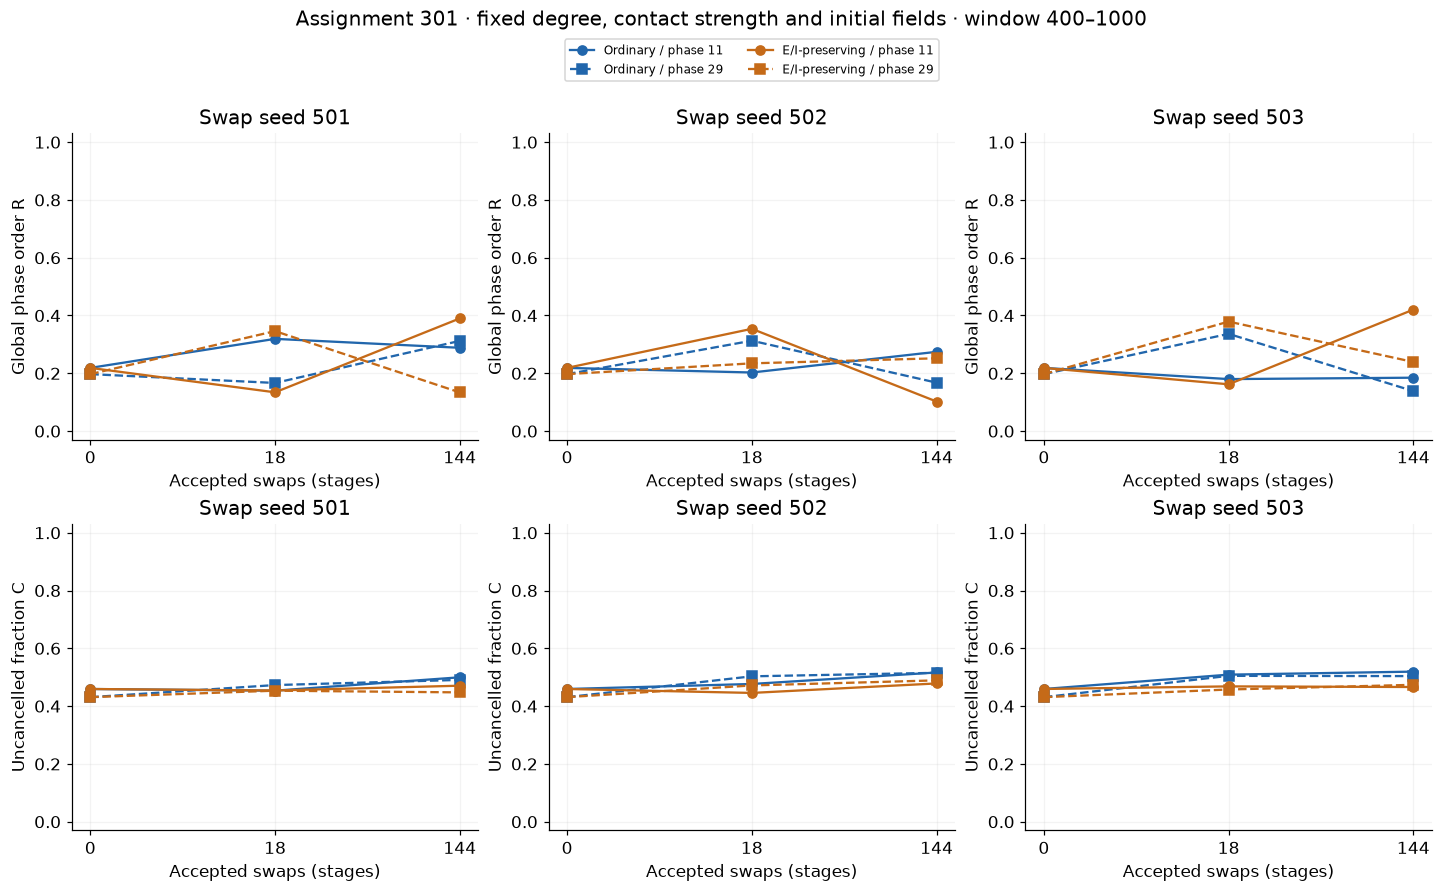

In [12]:
fig,axs=plt.subplots(2,3,figsize=(13,8),layout='constrained');xx=np.arange(3)
for col,swap_seed in enumerate(SWAP_SEEDS):
 for row,(metric,label) in enumerate([('phase_order_all','Global phase order R'),('local_uncancelled_fraction','Uncancelled fraction C')]):
  ax=axs[row,col]
  for kind in KINDS:
   for phase,marker,style in [(11,'o','-'),(29,'s','--')]:
    p=scan[(scan.layout=='random_301')&(scan.phase_seed==phase)]
    part=pd.concat([p[p.graph=='base'],p[(p.kind==kind)&(p.swap_seed==swap_seed)].sort_values('accepted_swaps')])
    ax.plot(xx,part[metric],marker=marker,linestyle=style,color=KIND_COLOR[kind],label=f'{KIND_LABEL[kind]} / phase {phase}')
  ax.set(xticks=xx,xticklabels=['0','18','144'],xlabel='Accepted swaps (stages)',ylabel=label,ylim=(-.03,1.03),title=f'Swap seed {swap_seed}')
axs[0,1].legend(fontsize=8,loc='lower center',bbox_to_anchor=(.5,1.15),ncol=2)
fig.suptitle('Assignment 301 · fixed degree, contact strength and initial fields · window 400–1000')
save(fig,'03_paired_rewiring_dynamics')

## 6. Show changes relative to the matched base
Every point subtracts the base with the same initial phase field. Seed paths are individual deterministic realizations, not confidence intervals. Sign changes across paths or phase fields would limit any claim of a consistent rewiring effect.

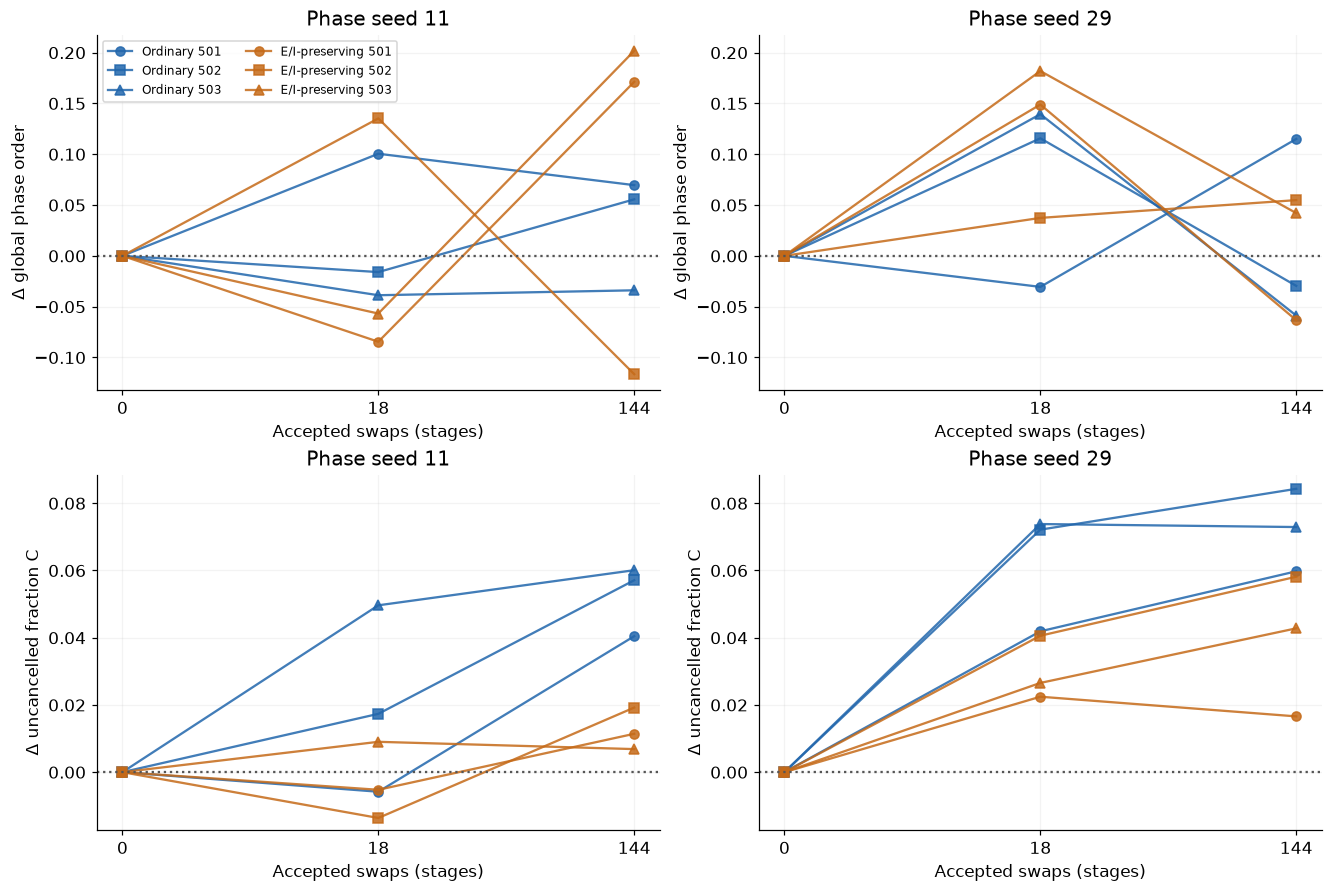

In [14]:
fig,axs=plt.subplots(2,2,figsize=(12,8),layout='constrained');xx=np.arange(3)
for col,phase in enumerate(PHASE_SEEDS):
 for row,(metric,label) in enumerate([('delta_phase_order_all','Δ global phase order'),('delta_local_uncancelled_fraction','Δ uncancelled fraction C')]):
  ax=axs[row,col]
  for kind in KINDS:
   for seed,marker in zip(SWAP_SEEDS,['o','s','^']):
    p=scan[(scan.layout=='random_301')&(scan.phase_seed==phase)]
    part=pd.concat([p[p.graph=='base'],p[(p.kind==kind)&(p.swap_seed==seed)].sort_values('accepted_swaps')])
    ax.plot(xx,part[metric],marker=marker,color=KIND_COLOR[kind],label=f'{KIND_LABEL[kind]} {seed}',alpha=.85)
  ax.axhline(0,color=GRAY,linestyle=':');ax.set(xticks=xx,xticklabels=['0','18','144'],xlabel='Accepted swaps (stages)',ylabel=label,title=f'Phase seed {phase}')
axs[0,0].legend(fontsize=8,ncol=2)
for row in range(2):
 low=min(ax.get_ylim()[0] for ax in axs[row,:]);high=max(ax.get_ylim()[1] for ax in axs[row,:])
 for ax in axs[row,:]:ax.set_ylim(low,high)
save(fig,'04_changes_from_matched_base')

## 7. Check ordinary paths under a second E/I assignment
Reusing the same ordinary graphs with assignment 302 tests sensitivity to source placement. The constrained paths are excluded because their constraint was constructed for assignment 301. Values are paired changes from each assignment/phase's own base. Two assignments are not a source-placement ensemble sufficient for inference.

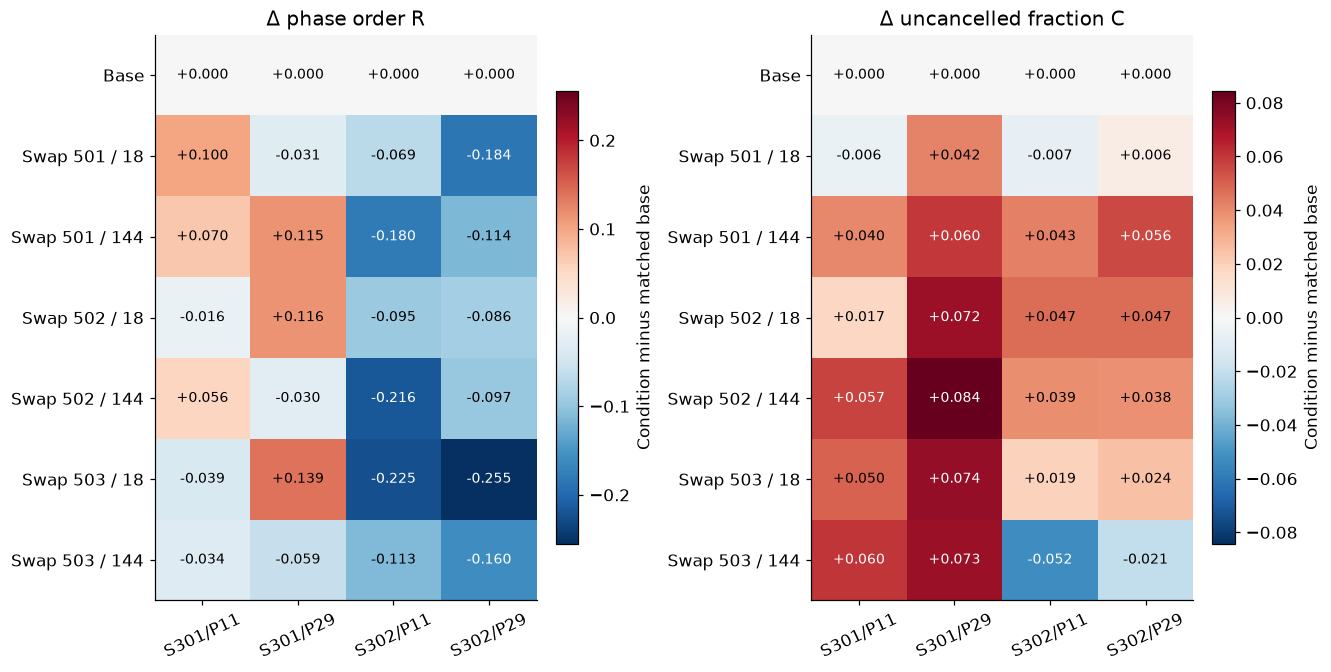

In [16]:
keys=['base']+[f'ordinary_{seed}_{level}' for seed in SWAP_SEEDS for level in LEVELS]
labels=['Base']+[f'Swap {seed} / {level}' for seed in SWAP_SEEDS for level in LEVELS]
columns=[(layout,phase) for layout in LAYOUTS for phase in PHASE_SEEDS]
fig,axs=plt.subplots(1,2,figsize=(12,6),layout='constrained')
for ax,(metric,title) in zip(axs,[('delta_phase_order_all','Δ phase order R'),('delta_local_uncancelled_fraction','Δ uncancelled fraction C')]):
 data=np.array([[scan[(scan.graph==name)&(scan.layout==layout)&(scan.phase_seed==phase)][metric].iloc[0] for layout,phase in columns] for name in keys])
 limit=max(.01,float(abs(data).max()));im=ax.imshow(data,cmap='RdBu_r',vmin=-limit,vmax=limit,aspect='auto')
 for i in range(len(keys)):
  for j in range(4):ax.text(j,i,f'{data[i,j]:+.3f}',ha='center',va='center',fontsize=9,color='white' if abs(data[i,j])>.6*limit else 'black')
 ax.set(yticks=np.arange(len(keys)),yticklabels=labels,xticks=range(4),xticklabels=['S301/P11','S301/P29','S302/P11','S302/P29'],title=title);ax.tick_params(axis='x',rotation=25);ax.grid(False)
 fig.colorbar(im,ax=ax,shrink=.8,label='Condition minus matched base')
save(fig,'05_source_assignment_sensitivity')

## 8. Inspect event timing and population activation
Assignment 301, phase 11, window 800–1000: compare base and final ordinary/constrained paths for seed 501. Rasters group E then I rather than showing physical coordinates. Right panels show E/I mean v, not population synchrony by themselves. Blue denotes E and orange I in this figure.

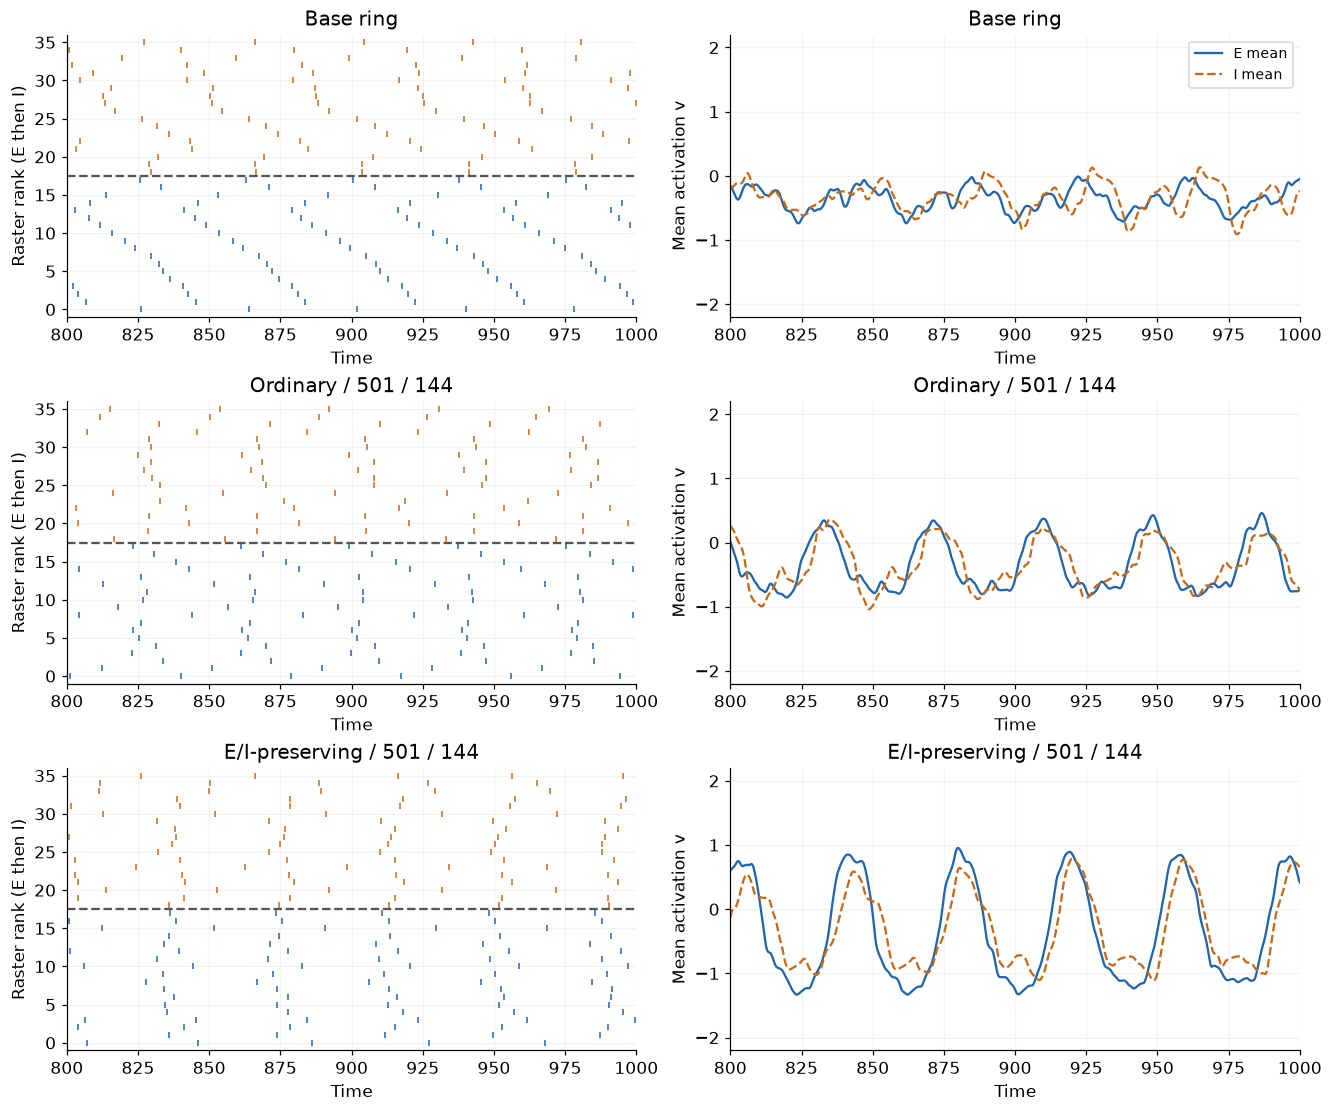

In [18]:
fig,axs=plt.subplots(3,2,figsize=(12,10),layout='constrained');times=np.linspace(800,1000,1001)
keys=['base','ordinary_501_144','ei_preserving_501_144'];titles=['Base ring','Ordinary / 501 / 144','E/I-preserving / 501 / 144']
for row,(name,title) in enumerate(zip(keys,titles)):
 sol=SELECTED[name];order=np.r_[np.flatnonzero(SOURCE),np.flatnonzero(~SOURCE)]
 for rank,node in enumerate(order):
  events=sol.t_events[node];events=events[(events>=800)&(events<=1000)]
  axs[row,0].plot(events,np.full(len(events),rank),'|',color=BLUE if SOURCE[node] else ORANGE,markersize=4)
 axs[row,0].axhline(17.5,color=GRAY,linestyle='--');axs[row,0].set(xlim=(800,1000),ylim=(-1,N),xlabel='Time',ylabel='Raster rank (E then I)',title=title)
 v=sol.sol(times).reshape(N,3,-1)[:,0]
 for pop,color,style,label in [(SOURCE,BLUE,'-','E mean'),(~SOURCE,ORANGE,'--','I mean')]:axs[row,1].plot(times,v[pop].mean(axis=0),color=color,linestyle=style,label=label)
 axs[row,1].set(xlim=(800,1000),ylim=(-2.2,2.2),xlabel='Time',ylabel='Mean activation v',title=title)
axs[0,1].legend(fontsize=9)
save(fig,'06_rasters_and_population_activation')

## 9. Validate rewiring and numerical contracts
Replay every accepted swap from the logged proposals. Check each intermediate graph for degree, connectivity and (when constrained) every node's E/I counts; compare checkpoint adjacency matrices with replay. Validate coupling contracts, source counts, paired baselines and sampled bounds.

For final constrained seed 501, compare independent Radau over 0–200 and tighter DOP853 over 0–1000. Extend base and both final seed-501 paths to time 2000. Early-window measurements use the original 1000-unit trajectories and their original event support; future events from an extended solution do not change the early phase-coverage rule.

,check,error,limit,passed
71,Zero baseline delta state_spread,0.000000e+00,1.000000e-12,True
72,"Sampled gates [0,1]",0.000000e+00,1.000000e-08,True
73,Sampled activation within reversals,0.000000e+00,1.000000e-08,True
74,Mean E current nonnegative,0.000000e+00,1.000000e-10,True
75,Mean I current nonpositive,0.000000e+00,1.000000e-10,True
76,Independent states 0–200,3.662220e-09,2.000000e-04,True
77,Independent events 0–200,3.530971e-09,2.000000e-04,True
78,Tighter states 0–1000,1.521588e-08,2.000000e-03,True
79,Tighter events 0–1000,1.135538e-08,2.000000e-03,True
80,base: early phase support consistent,0.000000e+00,1.000000e-12,True


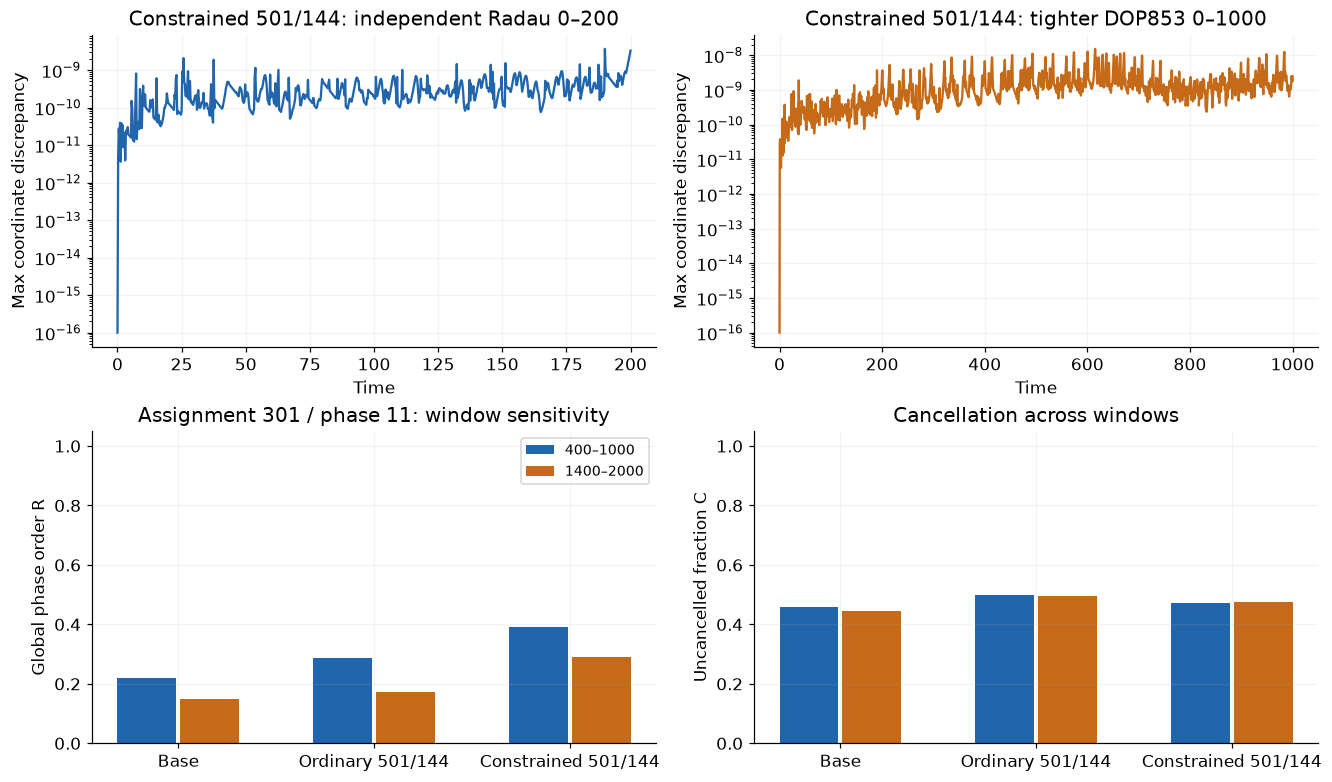

40 conditions; 83 checks passed.


In [20]:
checks=[]
def check(name,error,limit):checks.append(dict(check=name,error=float(error),limit=float(limit),passed=bool(error<limit)))
for name,A in ADJ.items():
 G=G_MATRICES[name]
 check(name+': simple symmetric adjacency',abs(A-A.T).max()+abs(np.diag(A)).max()+np.minimum(abs(A),abs(A-1)).max(),1e-12)
 check(name+': degree four',abs(A.sum(axis=1)-4).max(),1e-12)
 check(name+': connected',abs(nx.number_connected_components(GRAPHS[name])-1),.5)
 check(name+': row budget and edge strength',abs(G.sum(axis=1)-.08).max()+abs(G-.02*A).max(),1e-12)
 if name.startswith('ei_preserving'):check(name+': per-node E exposure preserved',abs(A@SOURCE.astype(int)-BASE_E_DEGREE).max(),1e-12)
replay_degree_error=0;replay_contact_error=0;replay_support_error=0;replay_connected_error=0;checkpoint_error=0;counter_error=0
for kind in KINDS:
 for seed in SWAP_SEEDS:
  g=BASE.copy();count=0;part=proposals[(proposals.kind==kind)&(proposals.swap_seed==seed)]
  for _,r in part.iterrows():
   if r.status=='accepted':
    a,b,c,d=map(int,[r.a,r.b,r.c,r.d])
    replay_support_error=max(replay_support_error,int(not (g.has_edge(a,b) and g.has_edge(c,d))),int(g.has_edge(a,d) or g.has_edge(c,b)),int(len({a,b,c,d})!=4))
    g.remove_edges_from([(a,b),(c,d)]);g.add_edges_from([(a,d),(c,b)]);count+=1
    A=nx.to_numpy_array(g,nodelist=range(N));replay_degree_error=max(replay_degree_error,float(abs(A.sum(axis=1)-4).max()))
    replay_connected_error=max(replay_connected_error,int(not nx.is_connected(g)))
    if kind=='ei_preserving':replay_contact_error=max(replay_contact_error,float(abs(A@SOURCE.astype(int)-BASE_E_DEGREE).max()))
    if count in LEVELS:checkpoint_error=max(checkpoint_error,float(abs(A-ADJ[f'{kind}_{seed}_{count}']).max()))
   counter_error=max(counter_error,abs(count-int(r.accepted_total)))
  counter_error=max(counter_error,abs(count-max(LEVELS)))
for name,error in [('Replay degree',replay_degree_error),('Replay E/I contacts',replay_contact_error),('Replay legal edge support',replay_support_error),('Replay connectivity',replay_connected_error),('Replay checkpoints',checkpoint_error),('Replay proposal counters',counter_error)]:check(name,error,1e-12)
for layout,mask in LAYOUTS.items():check(layout+': 18 E sources',abs(mask.sum()-18),.5)
check('40 conditions',abs(len(scan)-40),.5)
check('Four shared baseline conditions',abs((scan.graph=='base').sum()-4),.5)
for metric in DELTA_METRICS:check('Zero baseline delta '+metric,abs(scan[scan.graph=='base']['delta_'+metric]).max(),1e-12)
check('Sampled gates [0,1]',max(0.,-bound_table.min_s.min(),bound_table.max_s.max()-1),1e-8)
check('Sampled activation within reversals',max(0.,-3-bound_table.min_v.min(),bound_table.max_v.max()-3),1e-8)
check('Mean E current nonnegative',max(0.,-scan.mean_E_input.min()),1e-10)
check('Mean I current nonpositive',max(0.,scan.mean_I_input.max()),1e-10)
name='ei_preserving_501_144';G=G_MATRICES[name];E=np.where(SOURCE,3.,-3.);selected=SELECTED[name]
tshort=np.linspace(0,200,801);ref=integrate(INITIAL[11],G,E,end=200.,method='Radau',rtol=2e-11,atol=2e-13)
independent_error=float(abs(selected.sol(tshort)-ref.sol(tshort)).max());check('Independent states 0–200',independent_error,2e-4)
independent_events=0.
for e,er in zip(selected.t_events,ref.t_events):
 e=e[e<=200];assert len(e)==len(er)
 if len(e):independent_events=max(independent_events,float(abs(e-er).max()))
check('Independent events 0–200',independent_events,2e-4)
tfull=np.linspace(0,END,2001);tight=integrate(INITIAL[11],G,E,rtol=1e-12,atol=1e-14)
tight_error=float(abs(selected.sol(tfull)-tight.sol(tfull)).max());check('Tighter states 0–1000',tight_error,2e-3)
tight_events=0.
for e,er in zip(selected.t_events,tight.t_events):
 assert len(e)==len(er)
 if len(e):tight_events=max(tight_events,float(abs(e-er).max()))
check('Tighter events 0–1000',tight_events,2e-3)
window_rows=[]
WINDOW_KEYS=['base','ordinary_501_144','ei_preserving_501_144']
for name in WINDOW_KEYS:
 G=G_MATRICES[name];E=np.where(SOURCE,3.,-3.);long=integrate(INITIAL[11],G,E,end=2000.)
 for start,stop in [(400.,1000.),(1400.,2000.)]:
  stats,_=measure(SELECTED[name] if stop==END else long,SOURCE,G,start,stop)
  window_rows.append(dict(graph=name,layout='random_301',phase_seed=11,window=f'{int(start)}–{int(stop)}',**stats))
windows=pd.DataFrame(window_rows);windows.to_csv(OUT/'window_sensitivity.csv',index=False)
for name in WINDOW_KEYS:
 early=windows[(windows.graph==name)&(windows.window=='400–1000')].iloc[0]
 main=scan[(scan.graph==name)&(scan.layout=='random_301')&(scan.phase_seed==11)].iloc[0]
 check(name+': early phase support consistent',abs(early.phase_order_all-main.phase_order_all)+abs(early.phase_coverage_all-main.phase_coverage_all),1e-12)
validation=pd.DataFrame(checks);validation.to_csv(OUT/'validation_checks.csv',index=False);display(validation.tail(12));assert validation.passed.all()
fig,axs=plt.subplots(2,2,figsize=(12,7),layout='constrained')
axs[0,0].semilogy(tshort,np.maximum(np.max(abs(selected.sol(tshort)-ref.sol(tshort)),axis=0),1e-16),color=BLUE)
axs[0,0].set(xlabel='Time',ylabel='Max coordinate discrepancy',title='Constrained 501/144: independent Radau 0–200')
axs[0,1].semilogy(tfull,np.maximum(np.max(abs(selected.sol(tfull)-tight.sol(tfull)),axis=0),1e-16),color=ORANGE)
axs[0,1].set(xlabel='Time',ylabel='Max coordinate discrepancy',title='Constrained 501/144: tighter DOP853 0–1000')
xx=np.arange(3)
for window,color,offset in [('400–1000',BLUE,-.16),('1400–2000',ORANGE,.16)]:
 p=windows[windows.window==window].set_index('graph').loc[WINDOW_KEYS]
 axs[1,0].bar(xx+offset,p.phase_order_all,width=.3,color=color,label=window)
 axs[1,1].bar(xx+offset,p.local_uncancelled_fraction,width=.3,color=color)
for ax in axs[1,:]:ax.set(xticks=xx,xticklabels=['Base','Ordinary 501/144','Constrained 501/144'],ylim=(0,1.05))
axs[1,0].set(ylabel='Global phase order R',title='Assignment 301 / phase 11: window sensitivity');axs[1,0].legend(fontsize=9)
axs[1,1].set(ylabel='Uncancelled fraction C',title='Cancellation across windows')
save(fig,'07_accuracy_and_window_sensitivity')
summary=dict(versions=versions,nodes=N,edges=72,degree=4,recipient_budget=.08,edge_coefficient=.02,
 source_seeds=[301,302],phase_seeds=PHASE_SEEDS,swap_seeds=SWAP_SEEDS,accepted_swap_levels=LEVELS,
 rewiring_rules=KINDS,graphs=len(GRAPHS),unique_adjacencies=int(structure.adjacency_sha256.nunique()),
 primary_conditions=26,supplementary_conditions=14,conditions=len(scan),checks_passed=int(validation.passed.sum()),figures=7,
 duration=END,burn=BURN,sampling_step=DT,solver=dict(method='DOP853',rtol=1e-10,atol=1e-12,max_step=.25),
 parameters=dict(a=A_REC,b=B_REC,epsilon=EPS,current=.5,alpha=ALPHA,beta=BETA,width=WIDTH,E_E=3.,E_I=-3.),
 independent_horizon=200.,independent_state_error=independent_error,independent_event_error=independent_events,
 tighter_full_state_error=tight_error,tighter_full_event_error=tight_events)
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
_=(OUT/'progress.json').write_text(json.dumps(dict(status='complete',completed=len(scan),total=len(scan))))
print(len(scan),'conditions;',len(checks),'checks passed.')

## Limits and next extension
These are finite seeded paths, not uniform random graph samples, an asymptotic rewiring limit, or a causal decomposition into clustering versus path length. Three paths, two phase fields and two source assignments do not support confidence intervals or universal graph rankings. Snapshots on one path and matched baseline contrasts are correlated. The E/I constraint changes the accessible graph set and proposal acceptance, not just one scalar graph feature. The more restrictive rule may retain additional structure; no mixing or reachability theorem is asserted.

All graphs remain degree 4 and connected, but contact identities, motifs and state-dependent correlations can change. Preserving per-node E/I coefficient exposure does not preserve synaptic currents or establish biological balance. Finite-window R is not a proof of stable synchronization, and C is not an excitation–inhibition balance certificate. Numerical audits cover one selected trajectory and stated horizons. Discrepancy plots use a display floor of 10⁻¹⁶.

Next: broaden rewiring paths and source/phase replicates, then controlled degree, size and coupling-strength sweeps. Mixed neuronal models at nodes remain a later extension. Use the saved adjacency matrices and proposal logs to distinguish graph-generation changes from changes in integration or measurement. Exact seed reproducibility depends on recorded package versions; frozen matrices define this executed result.

References: [NetworkX double-edge swap definition](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.swap.double_edge_swap.html) (its standard function does not enforce connectivity; this notebook explicitly implements connectivity and source-type rejection); [Neuronal Dynamics: reversal currents and gates](https://neuronaldynamics.epfl.ch/online/Ch3.S1.html); [SciPy integration/events](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html). The particular constrained proposal rule, graph budgets and model parameters are specified here rather than justified as physiological calibration by those references.